# Porosity Classification Study

### Classify porosity into three levels
# - Class 0: Low (<0.5%)
# - Class 1: Medium (0.5–1.0%)
# - Class 2: High (>1.0%)

### Models: Logistic Regression, SVM, Random Forest, Gradient Boosting, MLP

## 1.Import Libraries

In [3]:
# load libraries
import pandas as pd
import numpy as np
import pathlib as Path
import matplotlib.pyplot as plt
import seaborn as sns
import os
from time import time 
import warnings
warnings.filterwarnings('ignore')


# Sklearn
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV

# preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Metrics
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay, precision_recall_curve, precision_recall_fscore_support

# Imbalanced data handling
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import joblib

# Plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')



## 2. Load Processing Data and create classification Labels

In [4]:
df = pd.read_csv("~/Documents/PlayTime/LMD_Modelling/data/processed/processed_data.csv")  
# features and continuous target
features = ["Power", "Speed", "Feed"]
X = df[features].copy()
y_continuous = df["porosity_%"].copy()

print(f"features shape: {X.shape}")
print(f"continuous target shape: {y_continuous.shape}")

# porosity distribution

print("Porosity distribution:")
print(y_continuous.describe())  
print(f"\nMin: {y_continuous.min():.2f}%, Max: {y_continuous.max():.2f}%")


features shape: (89, 3)
continuous target shape: (89,)
Porosity distribution:
count    89.000000
mean      0.299607
std       0.466428
min       0.000000
25%       0.000000
50%       0.190000
75%       0.375000
max       3.285000
Name: porosity_%, dtype: float64

Min: 0.00%, Max: 3.29%


### 3. Create Three Class labels


Class distribution:
 Class 0 (Low (<0.5%)): 77 samples (86.52%)
 Class 1 (Medium (0.5%-1.5%)): 9 samples (10.11%)
 Class 2 (High (>1.5%)): 3 samples (3.37%)


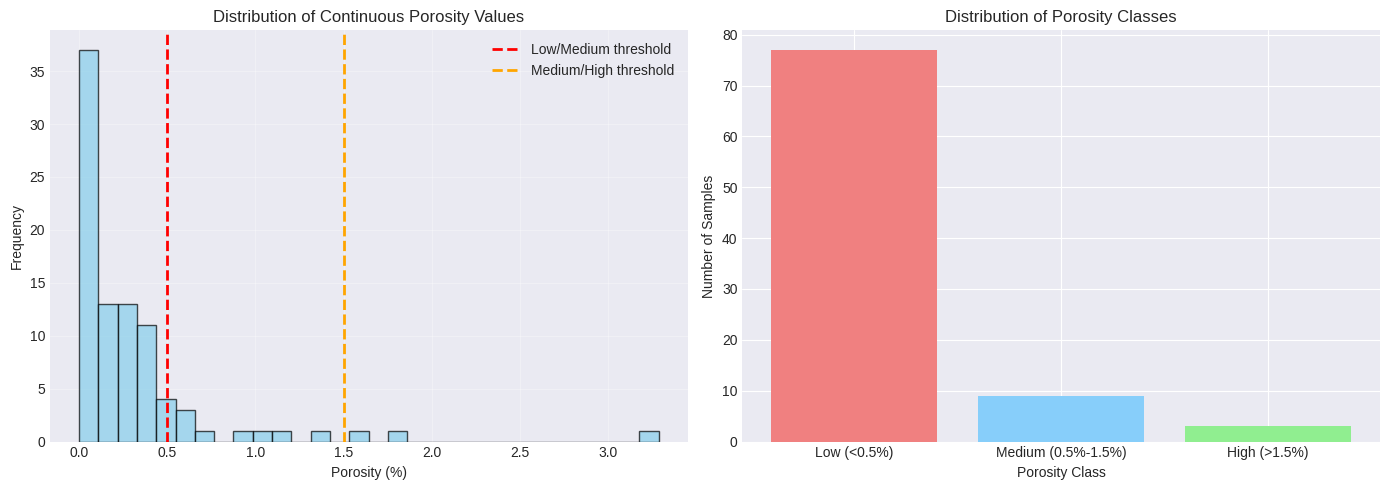

In [5]:


# Define porosity classes

def classify_porosity(porosity):
    """
    Classify porosity into three categories:
    0: Low (<0.5%)
    1: Medium (0.5% - 1%)
    2: High (>1.5%)
    """
    if porosity < 0.5:
        return 0  # Low
    elif 0.5 <= porosity <= 1.5:
        return 1  # Medium
    else:
        return 2  # High    
    
# Apply classification to the continuous target
y = y_continuous.apply(classify_porosity)

# class distribution
class_counts = y.value_counts().sort_index()
class_names = ['Low (<0.5%)', 'Medium (0.5%-1.5%)', 'High (>1.5%)']
print("\nClass distribution:")      

for cls, count in class_counts.items():
    print(f" Class {cls} ({class_names[cls]}): {count} samples ({(count/len(y))*100:.2f}%)")


# Visualize class distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,5))

# Histogram of continuous porosity with thresholds

ax1.hist(y_continuous, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
ax1.axvline(0.5, color='red', linestyle='--', linewidth=2, label='Low/Medium threshold ')
ax1.axvline(1.5, color='orange', linestyle='--', linewidth=2, label='Medium/High threshold')
ax1.set_xlabel('Porosity (%)')
ax1.set_ylabel('Frequency')
ax1.set_title('Distribution of Continuous Porosity Values')
ax1.legend()
ax1.grid(True, alpha=0.3)  

# Bar chart of class counts
class_names = ['Low (<0.5%)', 'Medium (0.5%-1.5%)', 'High (>1.5%)']
bars = ax2.bar(class_names, class_counts.values, color=['lightcoral', 'lightskyblue', 'lightgreen'])
ax2.set_xlabel('Porosity Class')
ax2.set_ylabel('Number of Samples')
ax2.set_title('Distribution of Porosity Classes')

plt.tight_layout()
plt.show()

## 4. Train-Test Stratified

In [6]:
# Train test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)   # ✓ Preserve class distribution

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples\n")

print("Training set class distribution:")
print(y_train.value_counts().sort_index())
print("\nTest set class distribution:")
print(y_test.value_counts().sort_index())   


Training set size: 71 samples
Test set size: 18 samples

Training set class distribution:
porosity_%
0    62
1     7
2     2
Name: count, dtype: int64

Test set class distribution:
porosity_%
0    15
1     2
2     1
Name: count, dtype: int64


## 5. Classification Models with Imbalance Handling


In [7]:
# Define classifiers with Imbalance Handling

# Stratified 5 Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) 


models = {}

#----------Logistic Regression (baseline)----------
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),  # Feature scaling
    ('lr', LogisticRegression(random_state=42, class_weight='balanced', multi_class='multinominal', solver='lbfgs'))
])

lr_params_grid = {
    'lr__C': [0.01, 0.1, 1, 10, 100],  # Regularization strength
    'lr__penalty': ['l2'],  # Regularization type
}

models['Logistic Regression'] = {
    'pipeline': lr_pipe,
    'params': lr_params_grid,
    'search_type': 'grid'
}


#----------SVM (RBF Kernel)----------

svm_pipe = Pipeline([
    ('scaler', StandardScaler()),  # Feature scaling
    ('svm', SVC(kernel='rbf', random_state=42, class_weight='balanced', probability=True)) # to enable probability estimates for ROC-AUC and precision-recall curves
])  

svm_params_grid = {
    'svm__C': [0.1, 1, 10, 100],  # Regularization strength
    'svm__gamma': ['scale', 'auto', 0.01, 0.1, 1],  # Kernel coefficient    
}

models["SVM"] = {
    'pipeline': svm_pipe,
    'params': svm_params_grid,
    'search_type': 'grid'
}

#----------Random Forest----------

rf_pipe = Pipeline([
    ('rf', RandomForestClassifier(random_state=42, class_weight='balanced')) # "balanced" to handle class imbalance
])  # StandardScaler is not needed for tree-based models

rf_params_grid = {
    'rf__n_estimators': [100, 200, 300],  # Number of trees
    'rf__max_depth': [None, 10, 20],  # Maximum depth of the tree
    'rf__min_samples_split': [2, 5],  # Minimum number of samples required to split an internal node
    'rf__min_samples_leaf': [1, 2, 4],  # Minimum number of samples required to be at a leaf node
}

models["Random Forest"] = {
    'pipeline': rf_pipe,
    'params': rf_params_grid,
    'search_type': 'random'  # Use RandomizedSearchCV instead of GridSearchCV for faster hyperparameter tuning
}

#----------Gradient Boosting (XGBoost)----------
gb_pipe = Pipeline([
    ('gb', GradientBoostingClassifier(random_state=42))  # Gradient Boosting does not have a built-in class_weight parameter, but it can handle imbalance to some extent through its boosting mechanism
])  # StandardScaler is not needed for tree-based models        
gb_params_grid = {
    'gb__n_estimators': [100, 200, 300],  # Number of boosting stages
    'gb__learning_rate': [0.01, 0.1, 0.2],  # Learning rate
    'gb__max_depth': [3, 5, 7],  # Maximum depth of the individual regression estimators
    'gb__min_samples_split': [2, 5],  # Minimum number of samples required to split an internal node
    'gb__min_samples_leaf': [1, 2, 4],  # Minimum number of samples required to be at a leaf node
}   
models["Gradient Boosting"] = {
    'pipeline': gb_pipe,
    'params': gb_params_grid,
    'search_type': 'random'  # Use RandomizedSearchCV instead of GridSearchCV for faster hyperparameter tuning
}

#----------Neural Network (MLP)----------
mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),  # Feature scaling is important for neural networks
    ('mlp', MLPClassifier(random_state=42, max_iter=2000, early_stopping=True, validation_fraction=0.15))  # early_stopping to prevent overfitting
])

mlp_params_grid = {
    'mlp__hidden_layer_sizes': [(50,), (50,), (20,10), (100,), (50, 50)],  # Different architectures
    'mlp__activation': ['relu', 'tanh'],  # Activation functions
    'mlp__alpha': [0.0001, 0.001, 0.01],  # L2 regularization parameter
    'mlp__learning_rate_init': [0.001, 0.01],  # Initial learning rate
}

models["Neural Network"] = {
    'pipeline': mlp_pipe,
    'params': mlp_params_grid,
    'search_type': 'random'  # Use RandomizedSearchCV instead of GridSearchCV for faster hyperparameter tuning
}   


print(f"Configured {len(models)} models: {list(models.keys())}\n")






Configured 5 models: ['Logistic Regression', 'SVM', 'Random Forest', 'Gradient Boosting', 'Neural Network']



## 6. Hyperparameter Tuning and Cross Validation